In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [2]:
df=pd.read_csv('Titanic-Dataset.csv',usecols=['Age','Fare','Survived'])

In [3]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [4]:
df.isnull().sum()

Survived      0
Age         177
Fare          0
dtype: int64

In [5]:
df.isnull().mean()*100

Survived     0.00000
Age         19.86532
Fare         0.00000
dtype: float64

In [6]:
x=df.drop(columns=['Survived'])
y=df['Survived']

In [7]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=2)

In [8]:
# Create new columns 'Age_imputed' in both train and test sets, 
# initially copying the original 'Age' values. 

x_train['Age_imputed']=x_train['Age']
x_test['Age_imputed']=x_test['Age']

# This ensures the original 'Age' column stays untouched, 
# and all imputations/transformations will be applied only on 'Age_imputed'.

In [9]:
x_train.head()

,Age,Fare,Age_imputed
30,40.0,27.7208,40.0
10,4.0,16.7000,4.0
873,47.0,9.0000,47.0
182,9.0,31.3875,9.0
876,20.0,9.8458,20.0


In [10]:
x_train.shape

(712, 3)

In [32]:
x_train['Age'].isnull().sum()

148

In [11]:
x_test.shape

(179, 3)

In [33]:
x_test['Age'].isnull().sum()

29

In [12]:
# Identify the missing values in the 'Age_imputed' column of training data 
# and replace them by randomly sampling (with same count) from the non-missing 'Age' values
#x_train['Age'].isnull().sum() → gives the count of missing values in the Age column of x_train.
x_train['Age_imputed'][x_train['Age_imputed'].isnull()] = (
    x_train['Age'].dropna().sample(x_train['Age'].isnull().sum()).values
)

# Do the same for the test data: replace missing values in 'Age_imputed' of test set 
# by randomly sampling from the non-missing 'Age' values of the TRAIN set with the same count 
#of missing values in the Age column of X-test set
# (important: ensures train-test consistency, avoids data leakage from test set itself)
x_test['Age_imputed'][x_test['Age_imputed'].isnull()] = (
    x_train['Age'].dropna().sample(x_test['Age'].isnull().sum()).values
)


C:\Users\banik\AppData\Local\Temp\ipykernel_3492\795776241.py:3: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  x_train['Age_imputed'][x_train['Age_imputed'].isnull()] = (
C:\Users\banik\AppData\Local\Temp\ipykernel_3492\795776241.py:10: Futu

In [13]:
x_train

,Age,Fare,Age_imputed
30,40.0,27.7208,40.0
10,4.0,16.7000,4.0
873,47.0,9.0000,47.0
182,9.0,31.3875,9.0
876,20.0,9.8458,20.0
...,...,...,...
534,30.0,8.6625,30.0
584,NaN,8.7125,21.0
493,71.0,49.5042,71.0
527,NaN,221.7792,30.0


C:\Users\banik\AppData\Local\Temp\ipykernel_3492\3070442571.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['Age'],label='Original',hist=False)
C:\Users\banik\AppData\Local\Temp\ipykernel_3492\3070442571.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['A

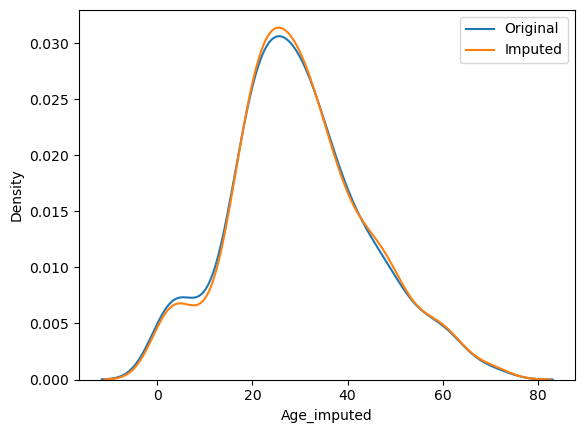

In [14]:
sns.distplot(x_train['Age'],label='Original',hist=False)
sns.distplot(x_train['Age_imputed'],label='Imputed',hist=False)
plt.legend()
plt.show()

In [15]:
print("original variable variance",x_train["Age"].var())
print("Imputed variable variance",x_test["Age_imputed"].var())

original variable variance 204.3495133904614
Imputed variable variance 232.49749103006715


In [16]:
x_train[['Fare','Age','Age_imputed']].cov()

,Fare,Age,Age_imputed
Fare,2368.246832,71.512440,53.100180
Age,71.512440,204.349513,204.349513
Age_imputed,53.100180,204.349513,202.969012


<Axes: >

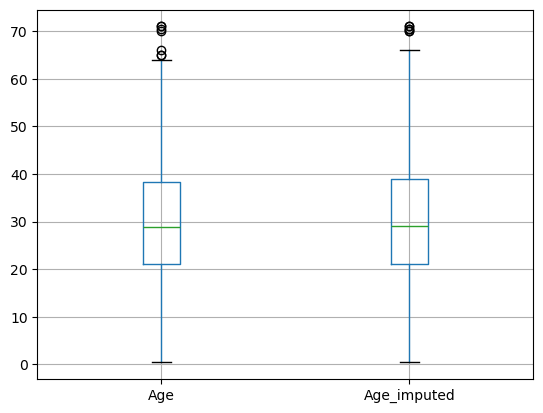

In [17]:
x_train[['Age','Age_imputed']].boxplot()

In [35]:
#what if the model gives diff output for same input because of random sampling
#(for particular fare ,particular age will be assigned)
sampled_value = x_train['Age'].dropna().sample(1, random_state=int(observation['Fare']))

NameError: name 'observation' is not defined

# For Categorical Data

In [19]:

data = pd.read_csv('train (1).csv',usecols=['GarageQual','FireplaceQu', 'SalePrice'])

In [20]:

data.head()

,FireplaceQu,GarageQual,SalePrice
0,NaN,TA,208500
1,TA,TA,181500
2,TA,TA,223500
3,Gd,TA,140000
4,TA,TA,250000


In [21]:
data.isnull().mean() * 100

FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64

In [22]:
X = data
Y = data['SalePrice']

In [23]:
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=2)

In [40]:
X_train['GarageQual_imputed'] = X_train['GarageQual']
X_test['GarageQual_imputed'] = X_test['GarageQual']

X_train['FireplaceQu_imputed'] = X_train['FireplaceQu']
X_test['FireplaceQu_imputed'] = X_test['FireplaceQu']

In [41]:
X_train.sample(4)

,FireplaceQu,GarageQual,SalePrice,GarageQual_imputed,FireplaceQu_imputed
265,TA,TA,175500,TA,TA
880,NaN,TA,157000,TA,NaN
1060,NaN,TA,213500,TA,NaN
818,NaN,TA,155000,TA,NaN


In [26]:
X_train['GarageQual_imputed'][X_train['GarageQual_imputed'].isnull()] = X_train['GarageQual'].dropna().sample(X_train['GarageQual'].isnull().sum()).values
X_test['GarageQual_imputed'][X_test['GarageQual_imputed'].isnull()] = X_train['GarageQual'].dropna().sample(X_test['GarageQual'].isnull().sum()).values

X_train['FireplaceQu_imputed'][X_train['FireplaceQu_imputed'].isnull()] = X_train['FireplaceQu'].dropna().sample(X_train['FireplaceQu'].isnull().sum()).values
X_test['FireplaceQu_imputed'][X_test['FireplaceQu_imputed'].isnull()] = X_train['FireplaceQu'].dropna().sample(X_test['FireplaceQu'].isnull().sum()).values

C:\Users\banik\AppData\Local\Temp\ipykernel_3492\856878696.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  X_train['GarageQual_imputed'][X_train['GarageQual_imputed'].isnull()] = X_train['GarageQual'].dropna().sample(X_train['GarageQual'

# One-liner explanation:
## This code compares the category distributions of GarageQual before and after imputation, and outputs a DataFrame showing the proportions side-by-side (original vs imputed). 
It calculates the relative frequency (probability) of each category in GarageQual by dividing its count by the total non-missing values before and after imputation

In [27]:

temp = pd.concat(
    [
        # Proportion of each category in the original 'GarageQual' column 
        # (excluding missing values)
        X_train['GarageQual'].value_counts() / len(X_train['GarageQual'].dropna()),

        # Proportion of each category in the imputed 'GarageQual_imputed' column 
        # (after filling missing values, so divide by full length)
        X_train['GarageQual_imputed'].value_counts() / len(X_train)
    ],
    axis=1
)

# Rename the columns for clarity: 'original' (before imputation) vs 'imputed' (after imputation)
temp.columns = ['original', 'imputed']


In [28]:

temp

,original,imputed
TA,0.951043,0.949486
Fa,0.037171,0.039384
Gd,0.009973,0.009418
Po,0.000907,0.000856
Ex,0.000907,0.000856


In [43]:
# dont use this random sample imputation if there is huge change in category distribution
#i.e huge missing vlaues
temp = pd.concat(
        [
            X_train['FireplaceQu'].value_counts() / len(X_train['FireplaceQu'].dropna()),
            X_train['FireplaceQu_imputed'].value_counts() / len(df)
        ],
        axis=1)

temp.columns = ['original', 'imputed']

temp

,original,imputed
Gd,0.494272,0.338945
TA,0.412439,0.282828
Fa,0.040917,0.028058
Po,0.027823,0.019080
Ex,0.024550,0.016835


C:\Users\banik\AppData\Local\Temp\ipykernel_3492\2559493575.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[X_train['FireplaceQu'] == category]['SalePrice'],hist=False,label=category)
C:\Users\banik\AppData\Local\Temp\ipykernel_3492\2559493575.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6

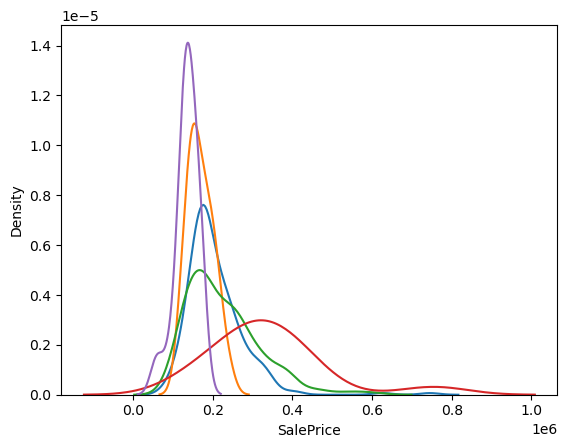

In [30]:
# For each unique non-missing category in 'FireplaceQu',
# plot the distribution curve of 'SalePrice' where 'FireplaceQu' equals that category.
# This helps compare how 'SalePrice' varies across different fireplace qualities.
# ``` 💜🔥🎉
for category in X_train['FireplaceQu'].dropna().unique():
    sns.distplot(X_train[X_train['FireplaceQu'] == category]['SalePrice'],hist=False,label=category)
plt.show()



C:\Users\banik\AppData\Local\Temp\ipykernel_3492\3530519742.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[X_train['FireplaceQu_imputed'] == category]['SalePrice'],hist=False,label=category)
C:\Users\banik\AppData\Local\Temp\ipykernel_3492\3530519742.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed29

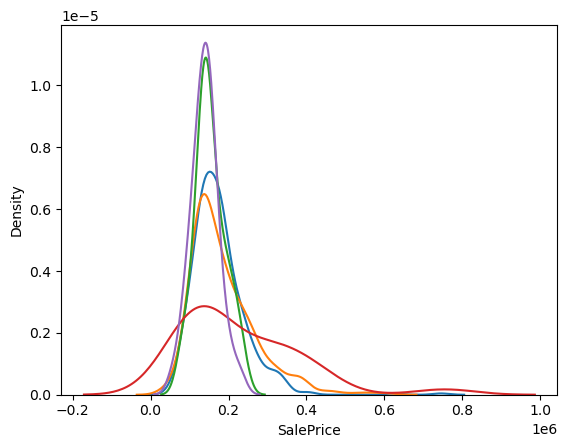

In [31]:

for category in X_train['FireplaceQu_imputed'].dropna().unique():
    sns.distplot(X_train[X_train['FireplaceQu_imputed'] == category]['SalePrice'],hist=False,label=category)
plt.show()